In [1]:
import requests  # 导入requests库，用于模拟浏览器进行网络请求
from lxml import etree  # 导入lxml库的etree模块，用于进行数据预处理
import csv  # 导入csv库，用于写入csv文件
import numpy as np  # 导入numpy库，用于进行数值计算
from collections import defaultdict  # 导入collections库的defaultdict类，用于创建默认字典
from datetime import datetime  # 导入datetime库，用于处理日期和时间
import matplotlib.pyplot as plt  # 导入matplotlib库的pyplot模块，用于绘制图形
from matplotlib import font_manager  # 导入matplotlib库的font_manager模块，用于管理字体
from matplotlib import rcParams  # 导入matplotlib库的rcParams模块，用于设置图形参数
from mpl_toolkits.mplot3d import Axes3D  # 导入mpl_toolkits库的mplot3d模块中的Axes3D类，用于创建3D图形
import imageio.v2 as imageio  # 导入imageio库的v2模块，用于读取和写入图像文件
from IPython.display import Image, display  # 导入IPython库的display模块，用于在Jupyter Notebook中显示图像
from wordcloud import WordCloud  # 导入wordcloud库，用于生成词云图
from PIL import Image
# 设置字体为支持减号的字体，例如"SimHei"
rcParams['font.sans-serif'] = ['SimHei']
font = font_manager.FontProperties(fname="C:/Windows/Fonts/simsun.ttc", size=14)  # 请将路径替换为你的字体文件路径
plt.rcParams['axes.unicode_minus'] = False  # 解决保存图像时负号'-'显示为方块的问题

In [2]:
def getWeather(url):
    weather_info = []   # 新建一个列表,将爬取的每月数据放进去
    # 请求头信息:浏览器版本型号,接收数据的编码格式
    headers = {
        # 必填,不填拿不到数据
        'User-Agent': 'Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.1 (KHTML, like Gecko) Chrome/14.0.835.163 Safari/535.1'
    }
    # 请求 接收到了响应数据
    resp = requests.get(url, headers=headers)
    # 数据预处理
    resp_html = etree.HTML(resp.text)
    # xpath提取所有数据
    resp_list = resp_html.xpath("//ul[@class='thrui']/li")
    # for循环迭代遍历
    for li in resp_list:
        day_weather_info = {}
        # 日期
        day_weather_info['date_time'] = li.xpath("./div[1]/text()")[0].split(' ')[0]
        # 最高气温 (包含摄氏度符号)
        high = li.xpath("./div[2]/text()")[0]
        day_weather_info['high'] = high[:high.find('℃')]
        # 最低气温
        low = li.xpath("./div[3]/text()")[0]
        day_weather_info['low'] = low[:low.find('℃')]
        # 天气
        day_weather_info['weather'] = li.xpath("./div[4]/text()")[0]
        weather_info.append(day_weather_info)
    return weather_info

In [3]:
# 循环获取数据
weathers = []
# for循环生成有顺序的1-12
for month in range(1, 13):
    # 获取某一月的天气信息
    # 三元表达式
    weather_time = '2023' + ('0' + str(month) if month < 10 else str(month))
    print(weather_time)
    url = f'https://lishi.tianqi.com/nanjing/{weather_time}.html'
    # 爬虫获取这个月的天气信息
    weather = getWeather(url)
    # 存到列表中
    weathers.append(weather)
print(weathers)

202301
202302
202303
202304
202305
202306
202307
202308
202309
202310
202311
202312
[[{'date_time': '2023-01-01', 'high': '9', 'low': '5', 'weather': '多云'}, {'date_time': '2023-01-02', 'high': '8', 'low': '0', 'weather': '多云'}, {'date_time': '2023-01-03', 'high': '10', 'low': '0', 'weather': '多云'}, {'date_time': '2023-01-04', 'high': '11', 'low': '3', 'weather': '多云'}, {'date_time': '2023-01-05', 'high': '12', 'low': '2', 'weather': '多云'}, {'date_time': '2023-01-06', 'high': '14', 'low': '1', 'weather': '多云'}, {'date_time': '2023-01-07', 'high': '16', 'low': '3', 'weather': '多云'}, {'date_time': '2023-01-08', 'high': '19', 'low': '4', 'weather': '多云'}, {'date_time': '2023-01-09', 'high': '15', 'low': '2', 'weather': '多云'}, {'date_time': '2023-01-10', 'high': '11', 'low': '3', 'weather': '晴'}, {'date_time': '2023-01-11', 'high': '14', 'low': '9', 'weather': '多云'}, {'date_time': '2023-01-12', 'high': '19', 'low': '11', 'weather': '小雨'}, {'date_time': '2023-01-13', 'high': '17', 'low': '6'

In [4]:
# 数据写入(一次性写入)
with open("weather.csv", "w",newline='') as csvfile:
    writer = csv.writer(csvfile)
    # 先写入列名:columns_name 日期 最高气温 最低气温  天气
    writer.writerow(["日期", "最高气温", "最低气温", '天气'])
    # 一次写入多行用writerows(写入的数据类型是列表,一个列表对应一行)
    writer.writerows([list(day_weather_dict.values()) for month_weather in weathers for day_weather_dict in month_weather])
print("写入成功！")

写入成功！


In [5]:
# 读取数据
with open("weather.csv", "r", newline='') as csvfile:
# with open("weather_test.csv", "r", newline='') as csvfile:
    reader = csv.reader(csvfile)
    # 跳过列名
    # next(reader)
    # 逐行读取数据
    read = []
    # for row in reader:
    #     if row:  # 检查行是否为空
    #         read.append(row)
    read = [
        row for row in reader # 检查行是否为空
        if any(cell.strip() for cell in row)]
print("读取成功!")
print(read)

读取成功!
[['日期', '最高气温', '最低气温', '天气'], ['2023-01-01', '9', '5', '多云'], ['2023-01-02', '8', '0', '多云'], ['2023-01-03', '10', '0', '多云'], ['2023-01-04', '11', '3', '多云'], ['2023-01-05', '12', '2', '多云'], ['2023-01-06', '14', '1', '多云'], ['2023-01-07', '16', '3', '多云'], ['2023-01-08', '19', '4', '多云'], ['2023-01-09', '15', '2', '多云'], ['2023-01-10', '11', '3', '晴'], ['2023-01-11', '14', '9', '多云'], ['2023-01-12', '19', '11', '小雨'], ['2023-01-13', '17', '6', '阴'], ['2023-01-14', '7', '-2', '雨夹雪'], ['2023-01-15', '0', '-5', '阴'], ['2023-01-16', '2', '-3', '晴'], ['2023-01-17', '5', '-3', '晴'], ['2023-01-18', '7', '-1', '晴'], ['2023-01-19', '11', '-1', '多云'], ['2023-01-20', '8', '0', '晴'], ['2023-01-21', '10', '5', '多云'], ['2023-01-22', '5', '3', '雾'], ['2023-01-23', '6', '-5', '小雨'], ['2023-01-24', '0', '-7', '多云'], ['2023-01-25', '0', '-3', '多云'], ['2023-01-26', '7', '-3', '多云'], ['2023-01-27', '4', '-6', '多云'], ['2023-01-28', '7', '-2', '晴'], ['2023-01-29', '11', '-1', '晴'], ['2023-01-30', '

In [6]:
# 数据标准化处理
original_data = read

# 初始化一个空列表来存储处理后的数据
formatted_data = []

# 遍历原始数据
for item in original_data[1:]:  # 从第二行开始，因为第一行是表头
    formatted_item = {
        '日期时间': item[0],
        '最高温度': item[1],
        '最低温度': item[2],
        '天气状况': item[3]
    }
    formatted_data.append(formatted_item)
# 打印处理后的数据
print(formatted_data[0])

{'日期时间': '2023-01-01', '最高温度': '9', '最低温度': '5', '天气状况': '多云'}


In [9]:
def show(date_time,high_temp,low_temp,weather):

# 绘制折线图
    plt.plot(date_time, high_temp, label='最高温度')
    plt.plot(date_time, low_temp, label='最低温度')
    plt.xlabel('日期时间')
    plt.ylabel('温度')
    plt.title(str(month)+'月最高温度和最低温度折线图')
    plt.legend()
    plt.savefig('plot_'+str(month)+'.jpg')  # 将图片保存
    plt.show()
    # print('plot_'+str(month)+'.jpg保存成功！')

# 使用scatter()函数绘制散点图
    plt.scatter(date_time, high_temp, label='最高温度')
    plt.scatter(date_time, low_temp, label='最低温度')
    # 添加颜色条
    cbar = plt.colorbar()
    cbar.set_label('Color Intensity')
    # 设置标题和标签
    plt.title(str(month)+'月最高温度和最低温度散点图')
    # 设置x轴和y轴的标签
    plt.xlabel('日期时间')
    plt.ylabel('温度')
    # 添加图例
    plt.legend()
    plt.savefig('scatter_'+str(month)+'.jpg')  # 将图片保存
    # 显示图形
    plt.show()
    # print('scatter_'+str(month)+'.jpg保存成功！')

# 绘制饼状图
    # 提取数据
    weather = [item['天气状况'] for item in monthly_data[month]]
    # 计算每个天气状况的数量
    weather_counts = {weather_type: weather.count(weather_type) for weather_type in set(weather)}
    plt.pie(weather_counts.values(), labels=weather_counts.keys(), autopct='%1.1f%%')
    plt.title(str(month)+'月天气状况分布饼状图')
    plt.savefig('pie_'+str(month)+'.jpg')  # 将图片保存
    plt.show()
    # print('pie_'+str(month)+'.jpg保存成功！')
    
# 绘制热力图
    # 整合最高温度和最低温度数据
    temp_range = np.array([high - low for high, low in zip(high_temp, low_temp)])
    # 创建一个新的图形
    plt.figure()
   
    plt.imshow(temp_range.reshape(-1, 1), cmap='hot', aspect='auto')
    # 设置x轴和y轴的标签
    plt.xlabel('日期时间')
    plt.ylabel('温度范围')
    # 添加颜色条
    plt.colorbar(label='温度差')
    # 添加标题
    plt.title(str(month)+'月最高温度和最低温度热力图')
    plt.savefig('hot_'+str(month)+'.jpg')  # 将图片保存
    # 显示图形
    plt.show()
    # print('hot_'+str(month)+'.jpg保存成功！')

#3D曲面图
    # 创建一个新的图形
    fig = plt.figure(figsize=(8,5),dpi=100)
    ax = fig.add_subplot(111, projection='3d')
    # 提取数据
    X = [item['日期时间'][-2:] for item in monthly_data[month]]
    Y = [int(item['最高温度']) for item in monthly_data[month]]
    Z = [int(item['最低温度']) for item in monthly_data[month]]
    # 绘制带有网格线的曲面图
    ax.plot_trisurf(X, Y, Z, cmap='viridis', edgecolor='none')
    ax.grid(True)
    plt.title(str(month)+'月最高温度和最低温度3D曲面图')
    # 设置x轴和y轴的标签
    ax.set_xlabel('日期时间')
    ax.set_ylabel('最高温度')
    ax.set_zlabel('最低温度')
    plt.savefig('3D_'+str(month)+'.jpg')  # 将图片保存
    # 显示图形
    plt.show()
    # print('3D_'+str(month)+'.jpg保存成功！')

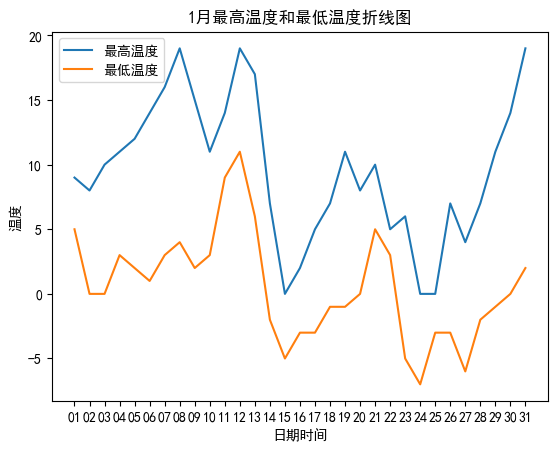

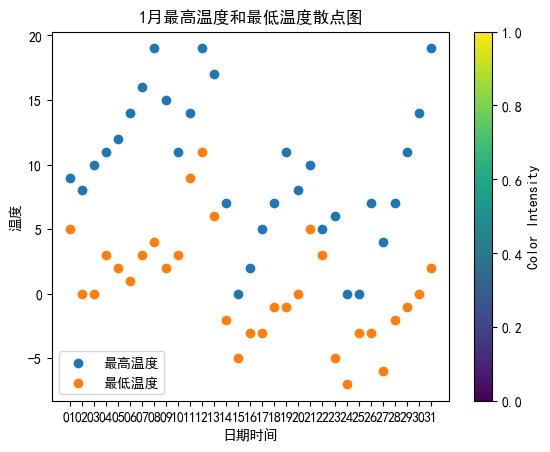

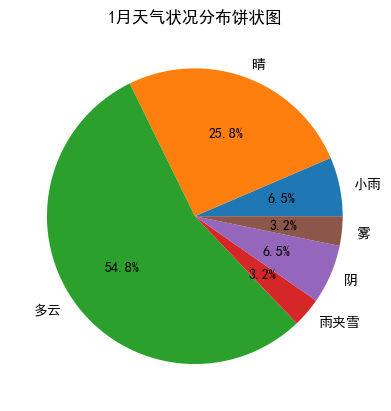

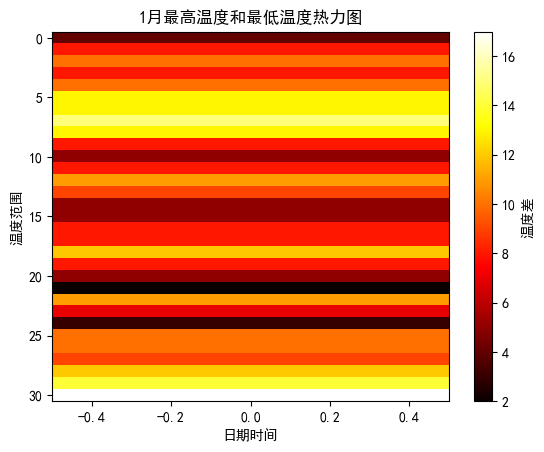

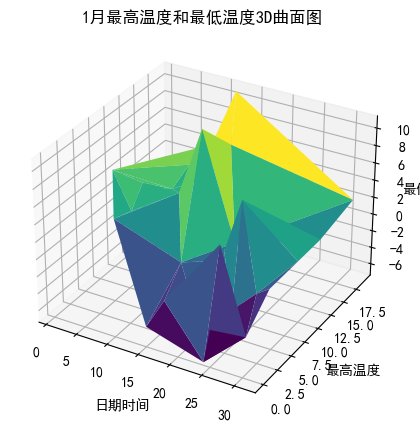

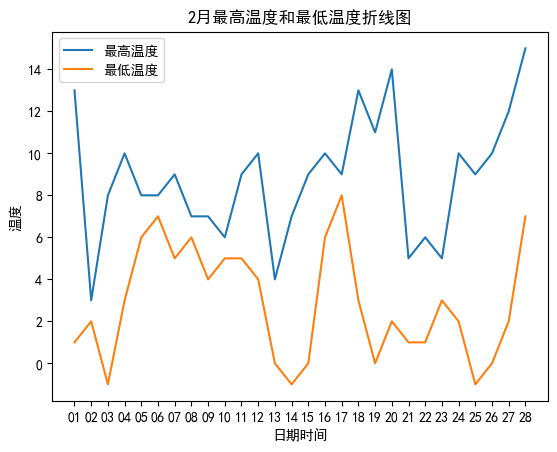

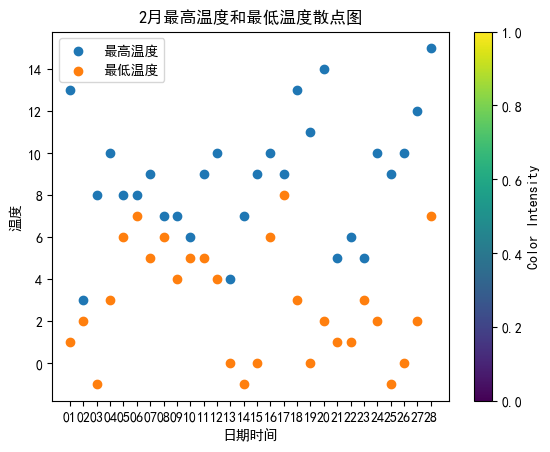

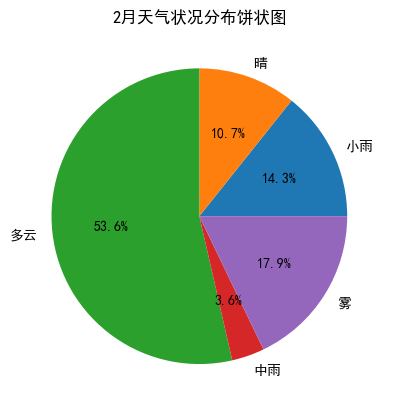

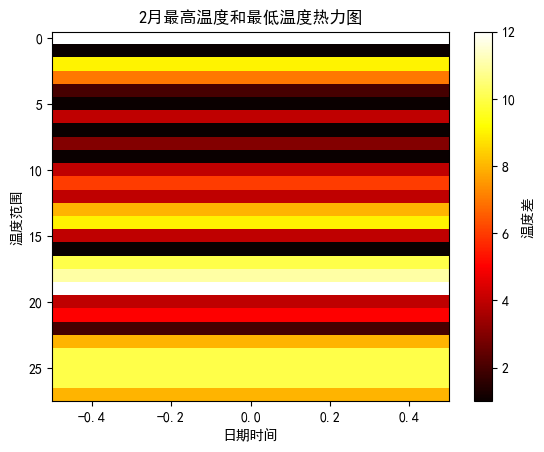

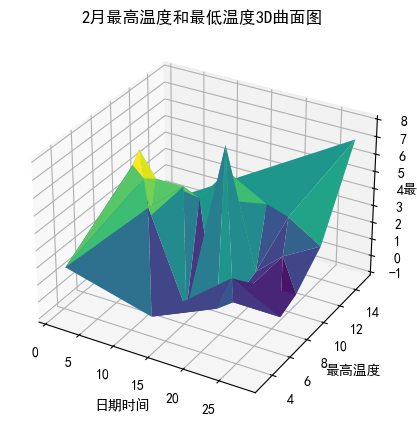

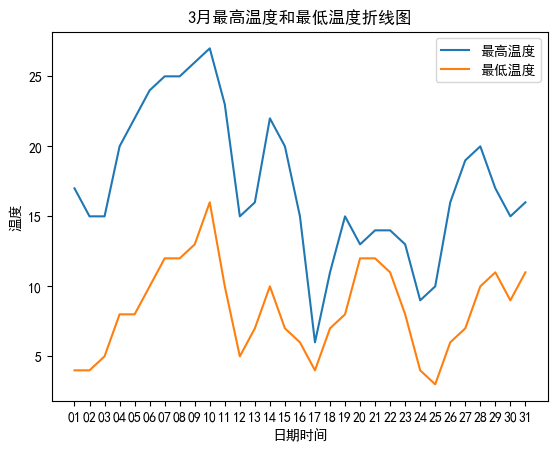

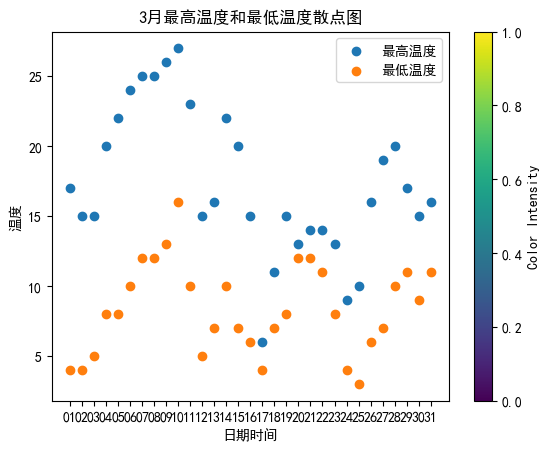

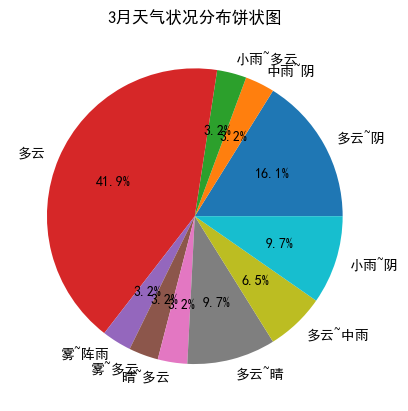

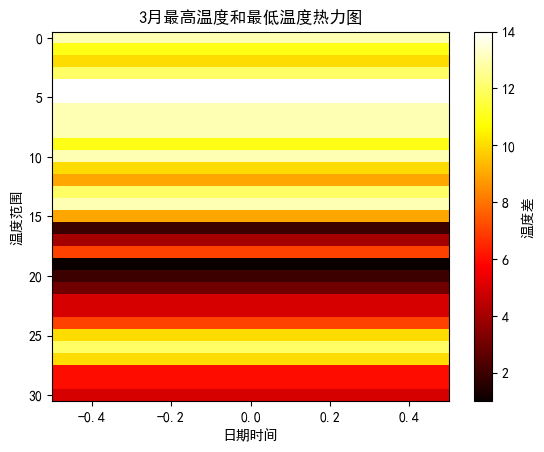

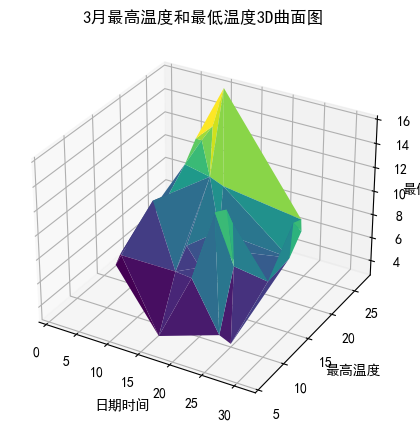

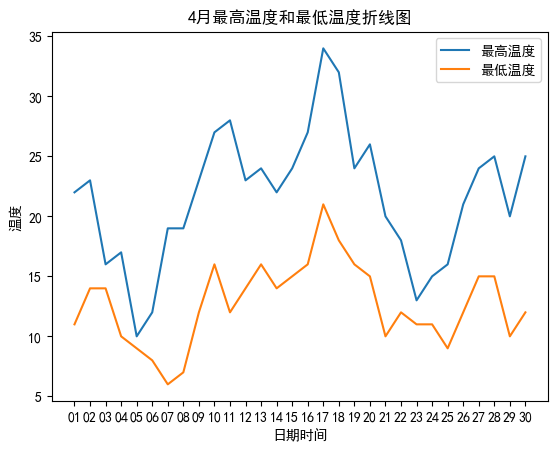

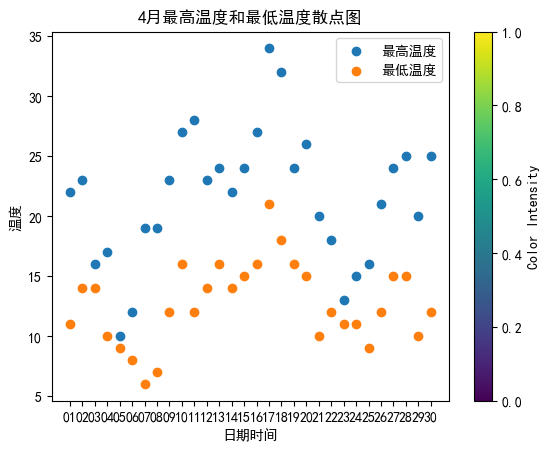

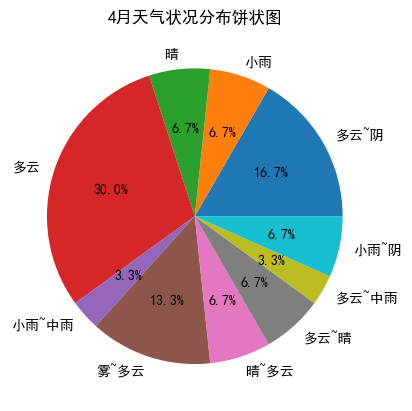

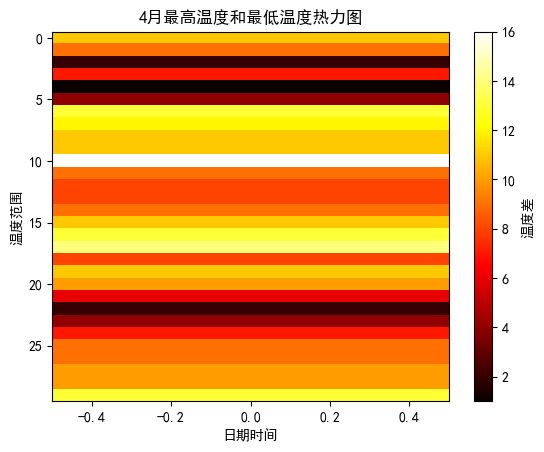

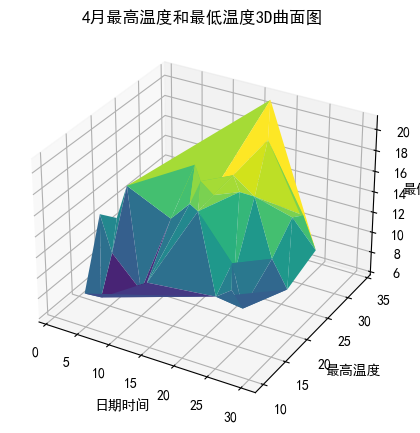

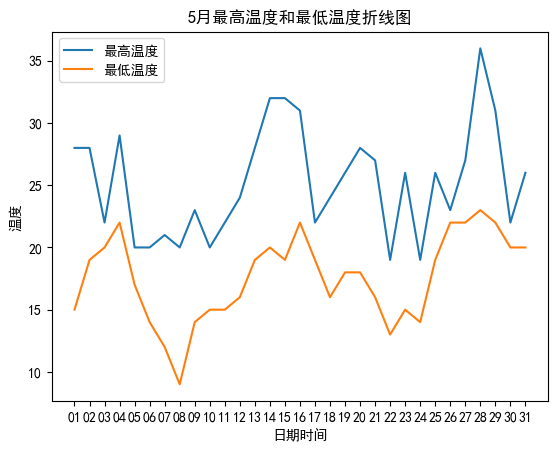

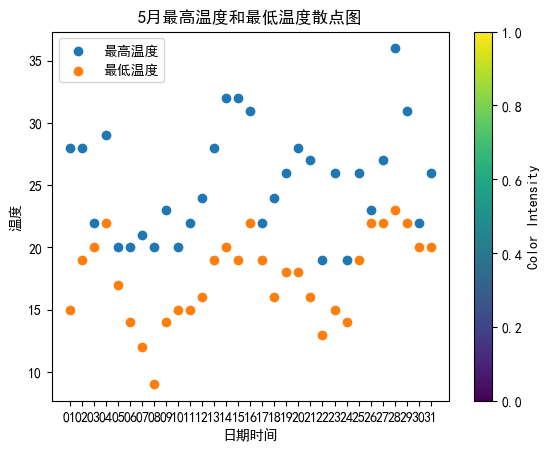

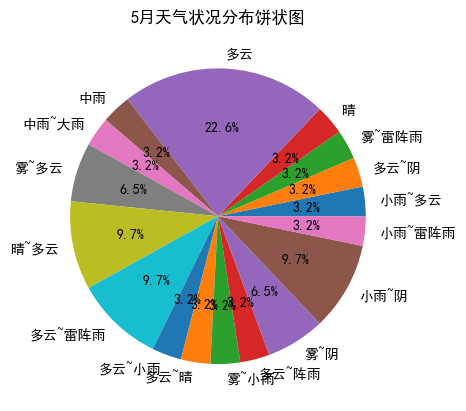

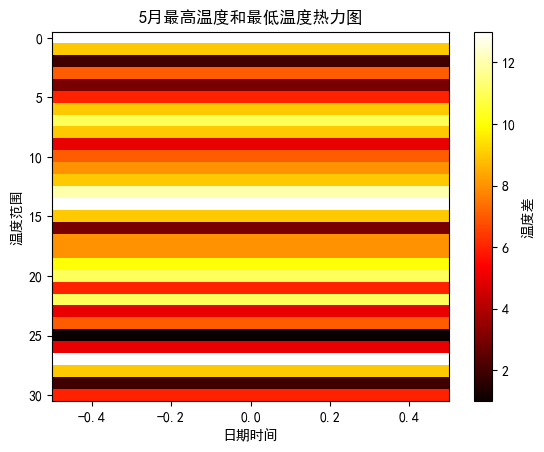

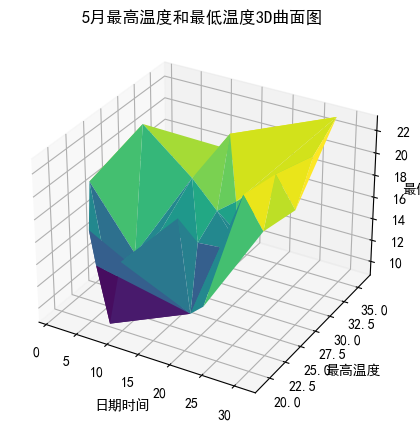

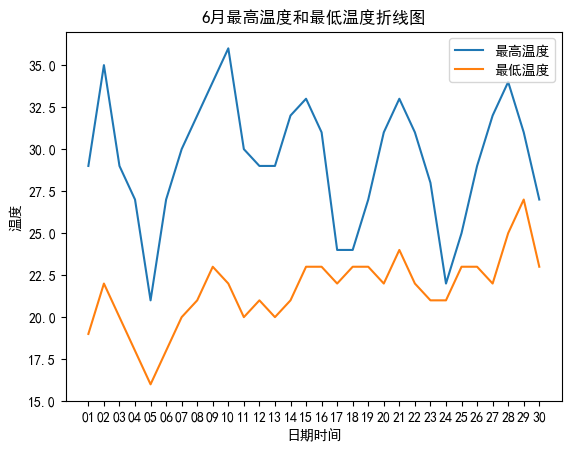

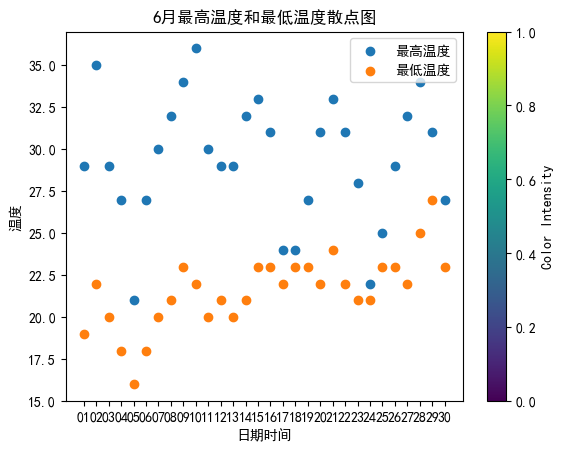

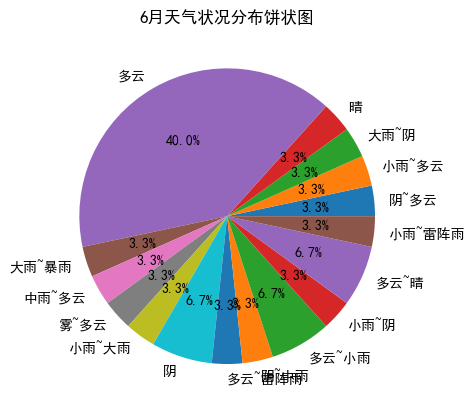

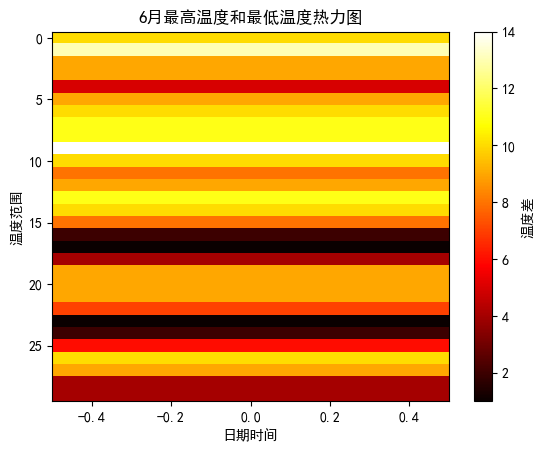

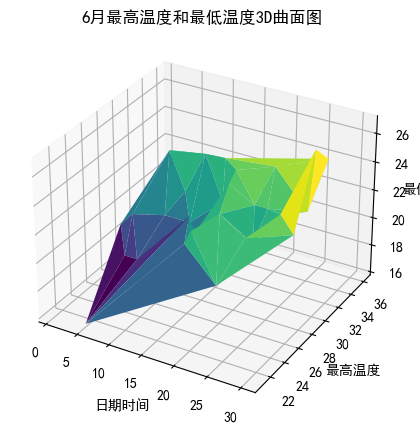

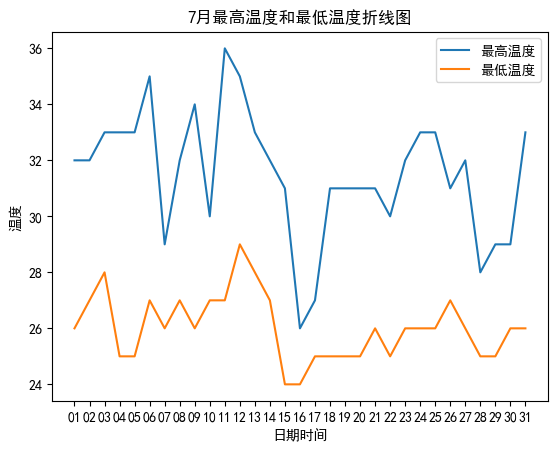

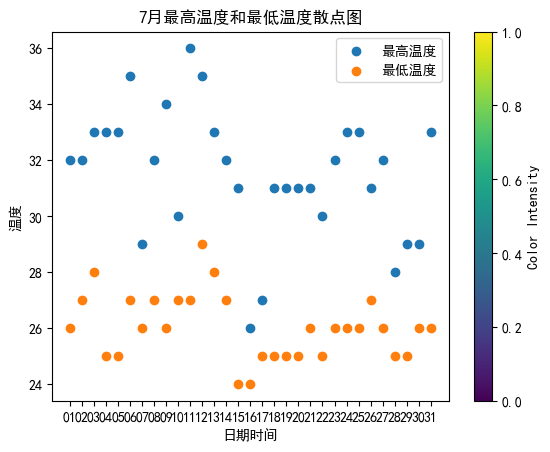

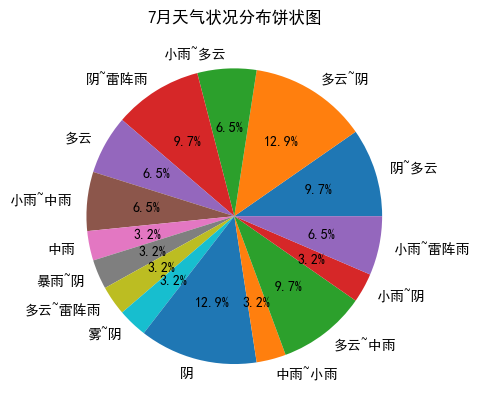

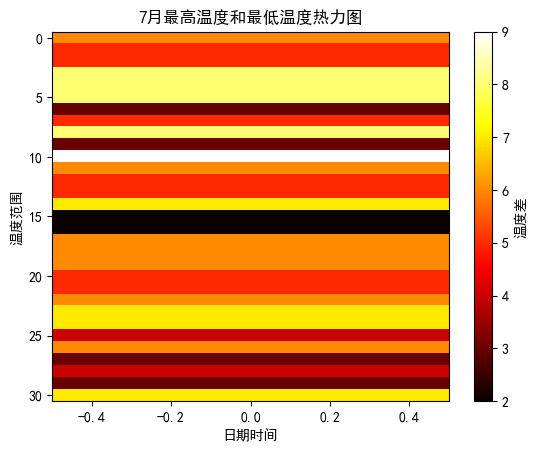

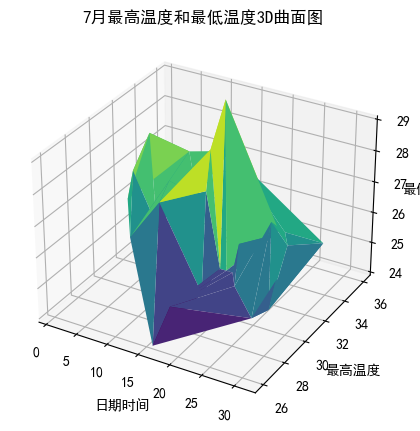

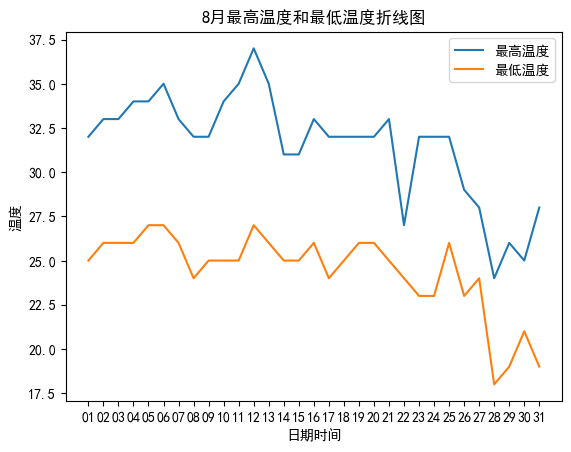

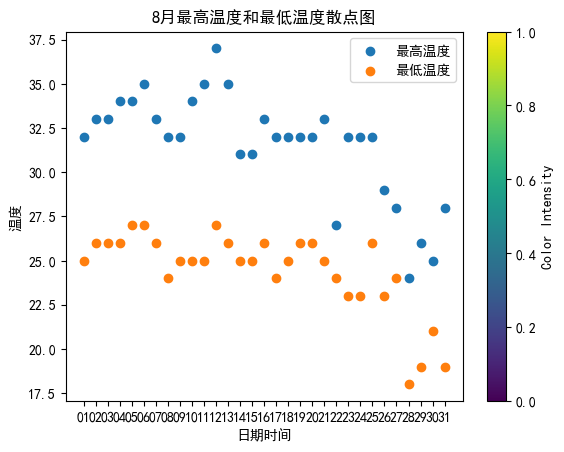

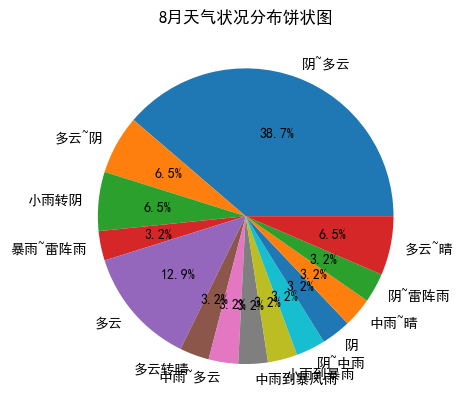

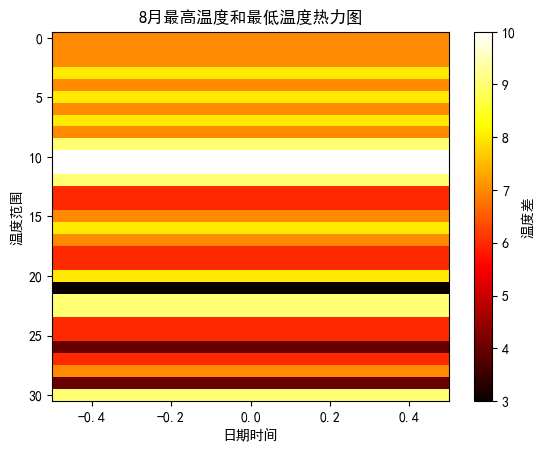

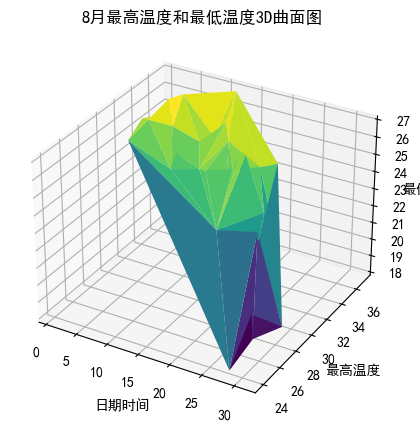

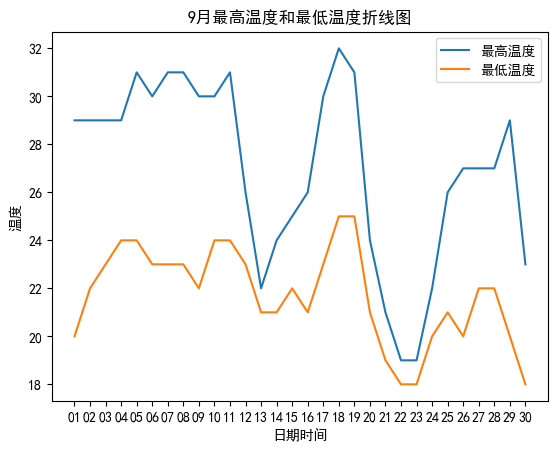

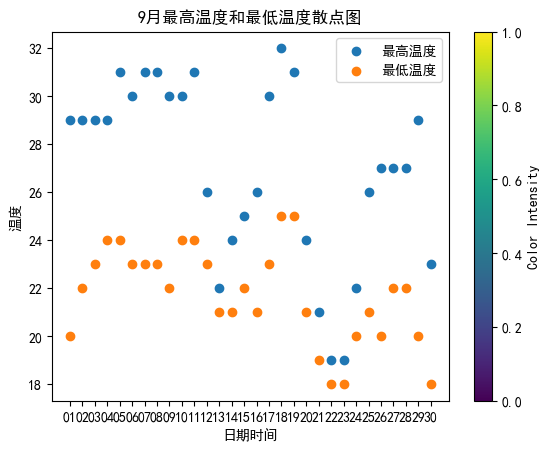

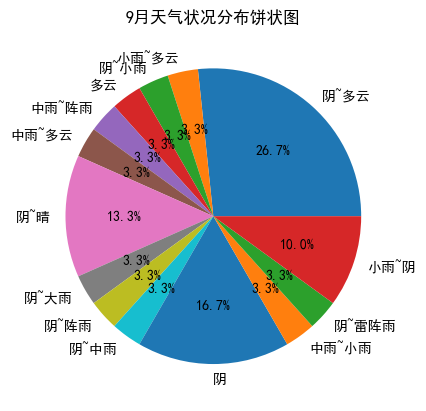

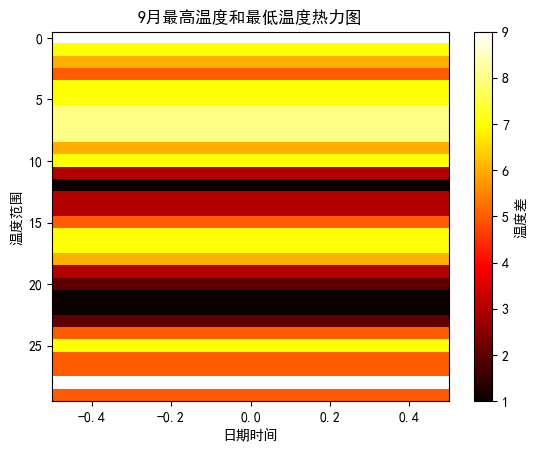

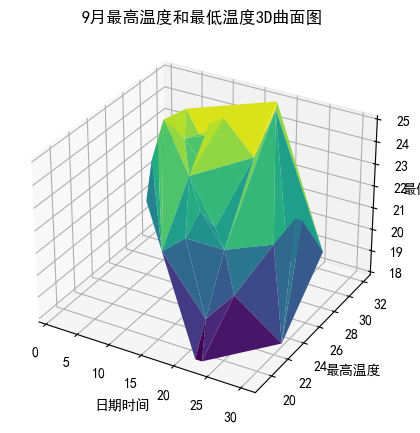

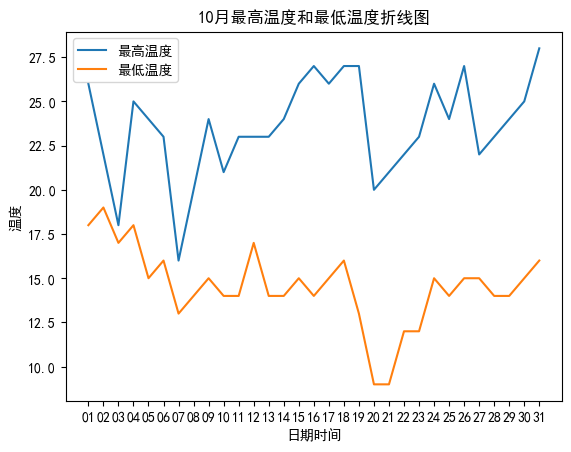

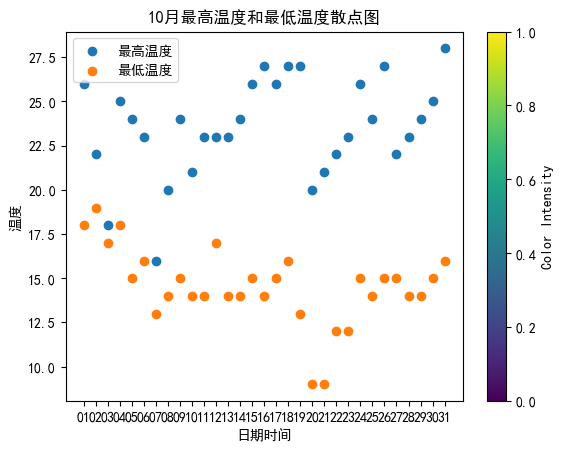

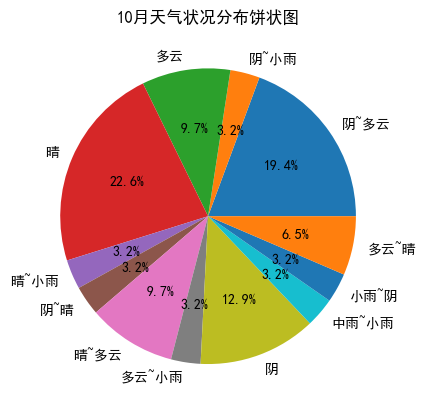

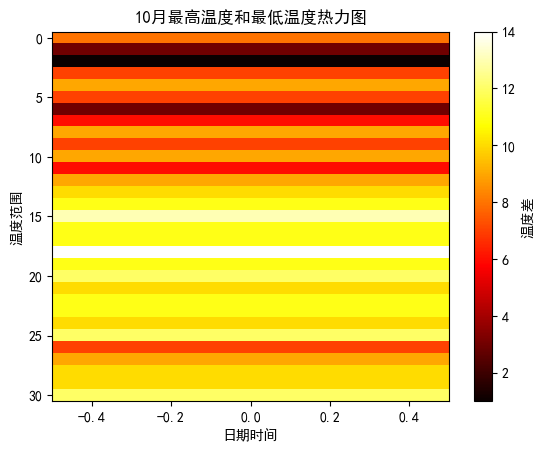

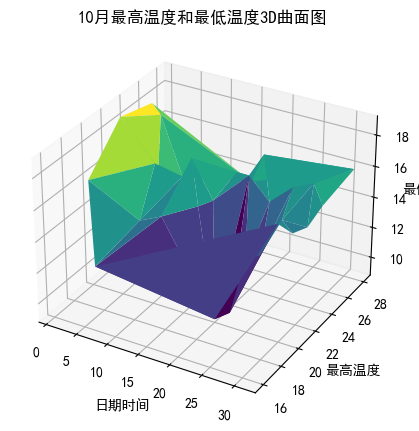

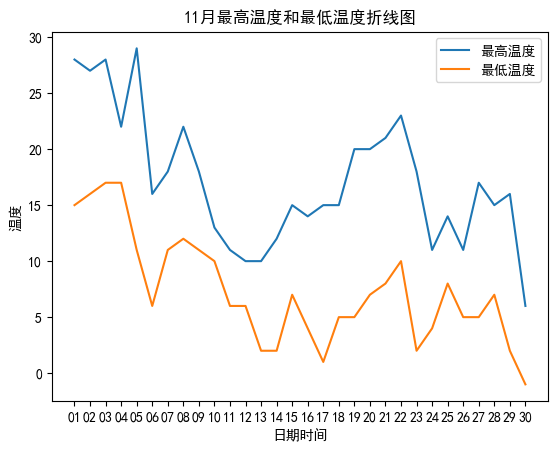

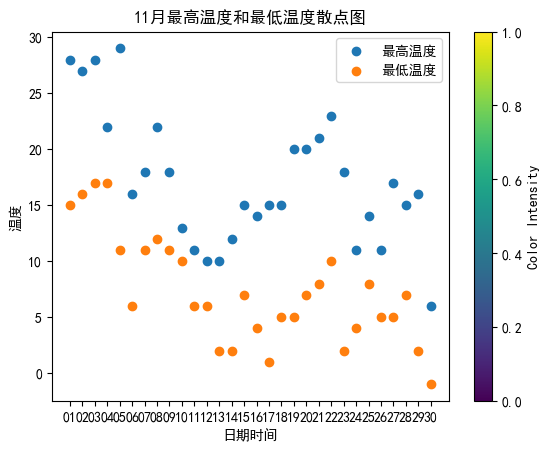

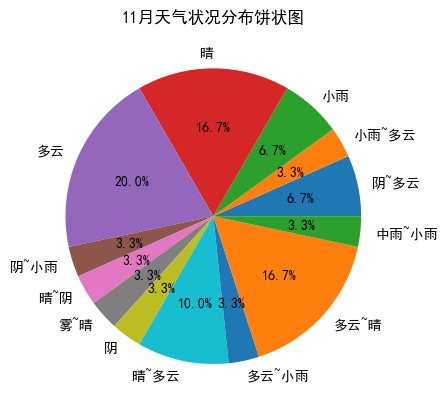

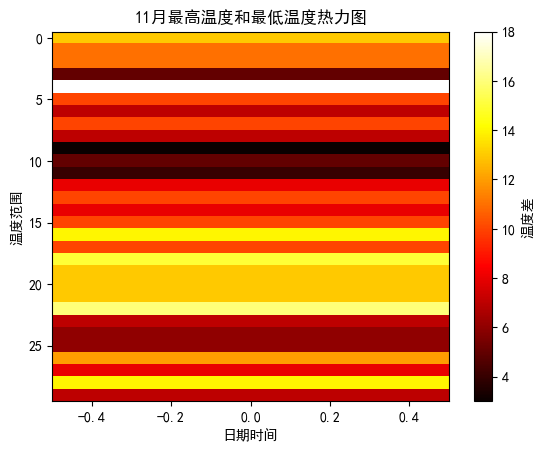

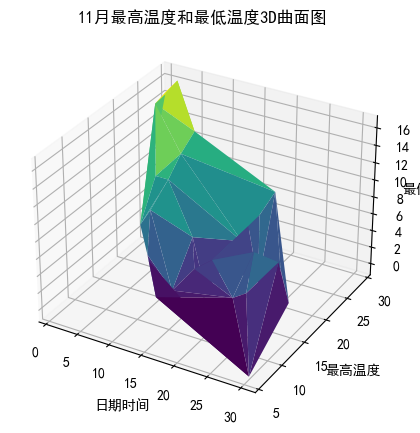

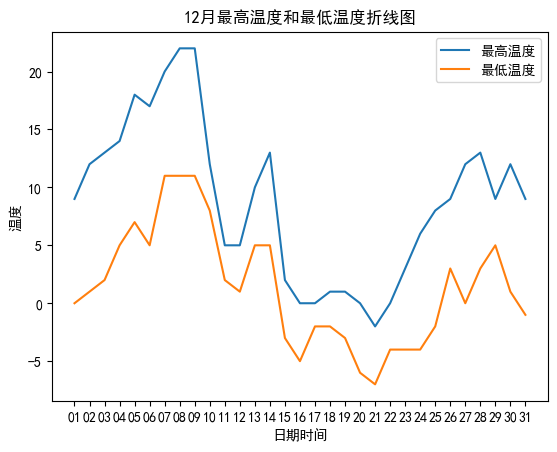

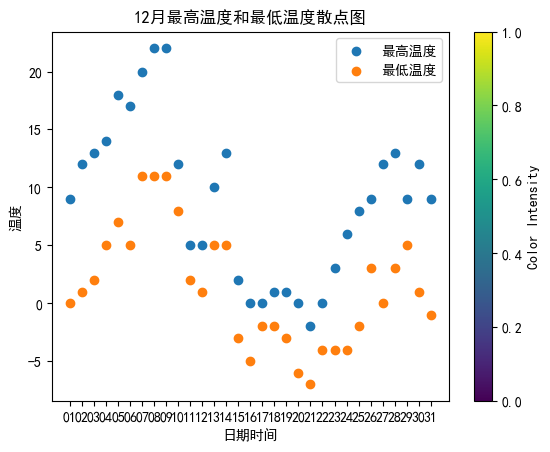

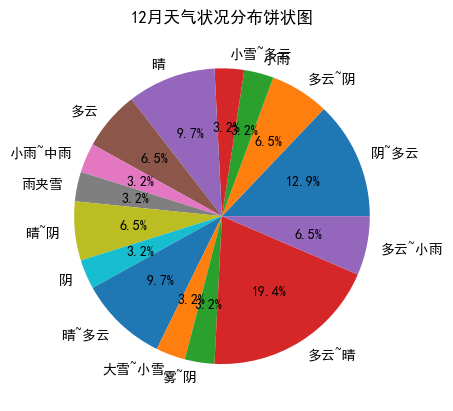

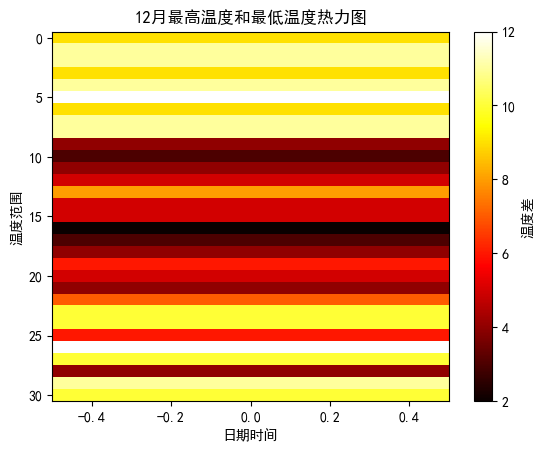

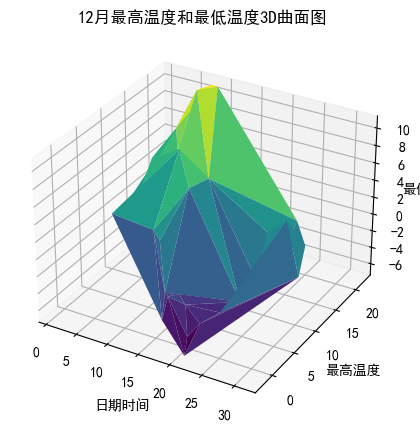

In [31]:
# 初始化 monthly_data 字典
monthly_data = defaultdict(list)
# 遍历 formatted_data，将日期时间字符串转换为月份并添加到 monthly_data 字典中
for item in formatted_data:
    month = datetime.strptime(item['日期时间'], '%Y-%m-%d').month
    if 1 <= month <= 12:
        monthly_data[month].append(item)

# 提取数据
for month in range(1, 13):
    date_time = [item['日期时间'][-2:] for item in monthly_data[month]]
    high_temp = [int(item['最高温度']) for item in monthly_data[month]]
    low_temp = [int(item['最低温度']) for item in monthly_data[month]]
    weather = [item['天气状况'] for item in monthly_data[month]]

    # 调用 show() 函数绘制折线图、散点图、饼状图和热力图、3D曲面图
    show(date_time, high_temp, low_temp, weather)


In [32]:
# 制作静态词云图方法
def generate_wordcloud(image_path, font_path, weather_data, save_path=None):
    # 读取字图片文件，生成轮廓
    mask_array = np.array(Image.open(image_path))
    
    # 从formatted_data变量中提取天气状况数据，将其转换为字符串
    weather = weather_data
    weather_str = ''.join(weather)
    
    # 生成词云图，并显示出来
    wordcloud = WordCloud(background_color='white', 
                          font_path=font_path, 
                          mask=mask_array,
                          max_words=len(weather_str)).generate(weather_str)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    
    # 如果提供了保存路径，则保存词云图
    if save_path:
        plt.savefig(save_path)
        print("词云图已保存至"+save_path)
    # else:
    #     plt.show()


词云图已保存至wordcloud.jpg


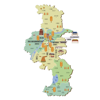

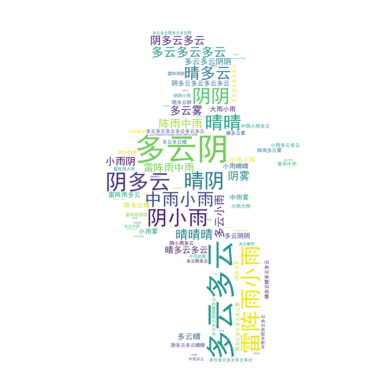

In [30]:
# 示例用法
# 生成静态词云图
image_path = "南京地图.jpg"
font_path = 'simhei.ttf'

weather_data = [item['天气状况'] for item in formatted_data]*2

# 调用函数时提供保存路径，将保存词云图为指定路径的文件
save_path = "wordcloud.jpg"
generate_wordcloud(image_path, font_path, weather_data, save_path)
display(Image.open(image_path).resize((100, 100)))